In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
df = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


In [4]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [5]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [9]:
print("Data Types:")
print(df.dtypes)

Data Types:
Id           int64
Area         int64
Bedrooms     int64
Bathrooms    int64
Floors       int64
YearBuilt    int64
Location       str
Condition      str
Garage         str
Price        int64
dtype: object


In [10]:
print("Location values:")
print(df["Location"].unique())

print("\nCondition values:")
print(df["Condition"].unique())

print("\nGarage values:")
print(df["Garage"].unique())

Location values:
<ArrowStringArray>
['Downtown', 'Suburban', 'Urban', 'Rural']
Length: 4, dtype: str

Condition values:
<ArrowStringArray>
['Excellent', 'Good', 'Fair', 'Poor']
Length: 4, dtype: str

Garage values:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [11]:
print("Numerical Summary:")
df.describe()

Numerical Summary:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [12]:
print("Price Summary:")
print(df["Price"].describe())

Price Summary:
count      2000.000000
mean     537676.855000
std      276428.845719
min       50005.000000
25%      300098.000000
50%      539254.000000
75%      780086.000000
max      999656.000000
Name: Price, dtype: float64


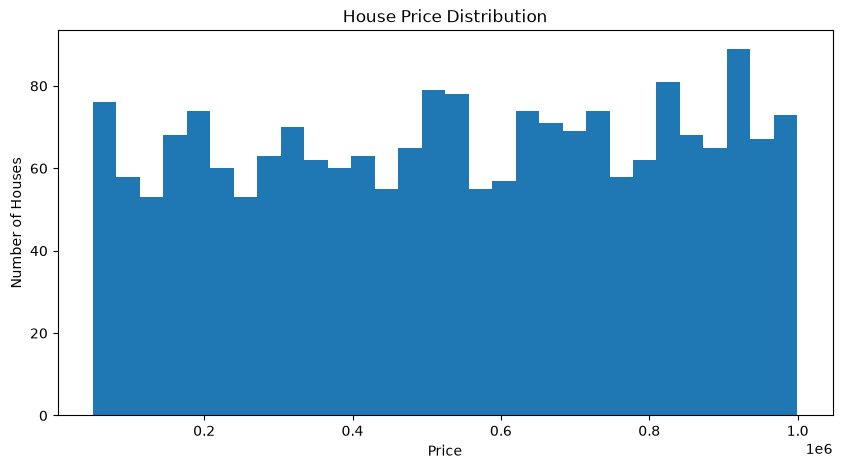

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(df["Price"], bins=30)

plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Houses")

plt.show()

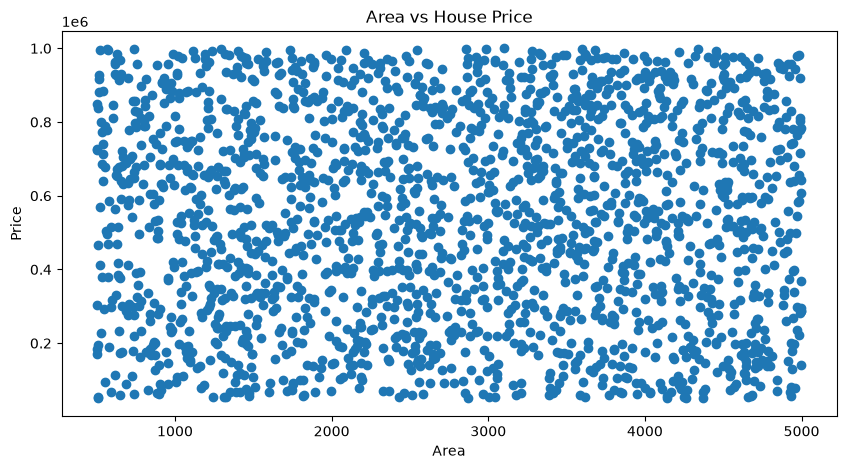

In [14]:
plt.figure(figsize=(10, 5))

plt.scatter(df["Area"], df["Price"])

plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")

plt.show()

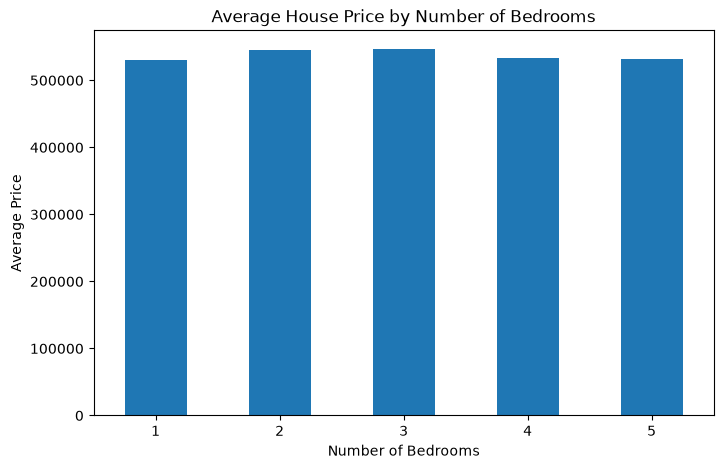

In [15]:
plt.figure(figsize=(8, 5))

df.groupby("Bedrooms")["Price"].mean().plot(kind="bar")

plt.title("Average House Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average Price")
plt.xticks(rotation=0)

plt.show()

In [16]:
location_encoder = LabelEncoder()
condition_encoder = LabelEncoder()
garage_encoder = LabelEncoder()

df["Location"] = location_encoder.fit_transform(df["Location"])
df["Condition"] = condition_encoder.fit_transform(df["Condition"])
df["Garage"] = garage_encoder.fit_transform(df["Garage"])

print("Categorical columns encoded successfully!")

Categorical columns encoded successfully!


In [17]:
X = df[[
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "YearBuilt",
    "Location",
    "Condition",
    "Garage"
]]

y = df["Price"]

print("Features and target selected successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Features and target selected successfully!
X shape: (2000, 8)
y shape: (2000,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Data split successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data split successfully!
Training data: (1600, 8)
Testing data: (400, 8)


In [19]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print("Random Forest Regression model created successfully!")

Random Forest Regression model created successfully!


In [20]:
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
Pred = model.predict(X_test)

print("Predicted House Prices:")
print(Pred[:10])

Predicted House Prices:
[643782.31 480025.71 511237.48 556045.42 517684.51 546099.05 497584.65
 657186.47 648152.84 666263.09]


In [22]:
mae = mean_absolute_error(y_test, Pred)
mse = mean_squared_error(y_test, Pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, Pred)

print("Model Evaluation")
print("------------------------")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R² Score:", r2)

Model Evaluation
------------------------
Mean Absolute Error: 253932.662325
Mean Squared Error: 86157199403.32457
Root Mean Squared Error: 293525.4663625025
R² Score: -0.10743569077376658


In [23]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": Pred
})

print("Actual vs Predicted House Prices:")
print(comparison.head(10))

Actual vs Predicted House Prices:
   Actual Price  Predicted Price
0        514764        643782.31
1        694256        480025.71
2         66375        511237.48
3        650243        556045.42
4        223285        517684.51
5        468127        546099.05
6        513002        497584.65
7        911525        657186.47
8        723265        648152.84
9        339416        666263.09


In [24]:
joblib.dump(model, "house_price_model.pkl")

print("House Price Random Forest model saved successfully!")

House Price Random Forest model saved successfully!


In [25]:
joblib.dump(location_encoder, "location_encoder.pkl")

print("Location encoder saved successfully!")

Location encoder saved successfully!


In [26]:
joblib.dump(condition_encoder, "condition_encoder.pkl")

print("Condition encoder saved successfully!")

Condition encoder saved successfully!


In [27]:
joblib.dump(garage_encoder, "garage_encoder.pkl")

print("Garage encoder saved successfully!")

Garage encoder saved successfully!


In [28]:
df.to_csv("house_price_processed.csv", index=False)

print("Processed house price dataset saved successfully!")

Processed house price dataset saved successfully!


In [29]:
import os

files = [
    "house_price_model.pkl",
    "location_encoder.pkl",
    "condition_encoder.pkl",
    "garage_encoder.pkl",
    "house_price_processed.csv"
]

print("Saved Files")
print("------------------------")

for file in files:
    if os.path.exists(file):
        print("✅", file)
    else:
        print("❌", file)

Saved Files
------------------------
✅ house_price_model.pkl
✅ location_encoder.pkl
✅ condition_encoder.pkl
✅ garage_encoder.pkl
✅ house_price_processed.csv


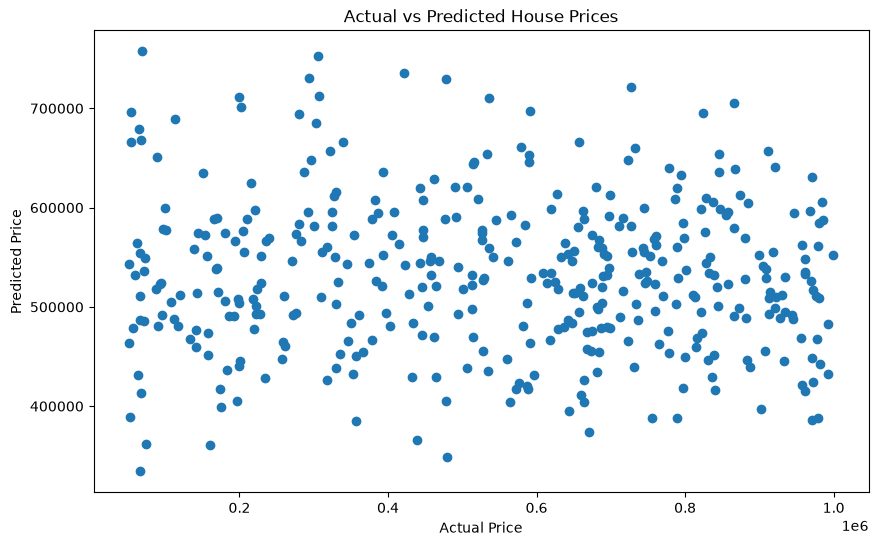

In [30]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, Pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [31]:
import os

print("House Price Prediction Project Files")
print("------------------------------------")

required_files = [
    "house_price_model.pkl",
    "location_encoder.pkl",
    "condition_encoder.pkl",
    "garage_encoder.pkl",
    "house_price_processed.csv"
]

for file in required_files:
    if os.path.exists(file):
        print("✅", file, "found")
    else:
        print("❌", file, "missing")

print("------------------------------------")
print("Project verification completed!")

House Price Prediction Project Files
------------------------------------
✅ house_price_model.pkl found
✅ location_encoder.pkl found
✅ condition_encoder.pkl found
✅ garage_encoder.pkl found
✅ house_price_processed.csv found
------------------------------------
Project verification completed!


In [33]:
%%writefile house_app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="House Price Prediction",
    page_icon="🏠",
    layout="wide"
)

st.title("🏠 House Price Prediction System")
st.write("Predict house prices using Random Forest Regression.")

# Load model
model = joblib.load("house_price_model.pkl")

# Load encoders
location_encoder = joblib.load("location_encoder.pkl")
condition_encoder = joblib.load("condition_encoder.pkl")
garage_encoder = joblib.load("garage_encoder.pkl")

st.subheader("Enter House Details")

area = st.number_input(
    "Area",
    min_value=100,
    max_value=10000,
    value=1500
)

bedrooms = st.number_input(
    "Bedrooms",
    min_value=1,
    max_value=10,
    value=3
)

bathrooms = st.number_input(
    "Bathrooms",
    min_value=1,
    max_value=10,
    value=2
)

floors = st.number_input(
    "Floors",
    min_value=1,
    max_value=5,
    value=1
)

year_built = st.number_input(
    "Year Built",
    min_value=1800,
    max_value=2026,
    value=2010
)

location = st.selectbox(
    "Location",
    location_encoder.classes_
)

condition = st.selectbox(
    "Condition",
    condition_encoder.classes_
)

garage = st.selectbox(
    "Garage",
    garage_encoder.classes_
)

if st.button("Predict House Price"):

    location_encoded = location_encoder.transform([location])[0]
    condition_encoded = condition_encoder.transform([condition])[0]
    garage_encoded = garage_encoder.transform([garage])[0]

    input_data = pd.DataFrame({
        "Area": [area],
        "Bedrooms": [bedrooms],
        "Bathrooms": [bathrooms],
        "Floors": [floors],
        "YearBuilt": [year_built],
        "Location": [location_encoded],
        "Condition": [condition_encoded],
        "Garage": [garage_encoded]
    })

    prediction = model.predict(input_data)[0]

    st.success(
        f"🏠 Estimated House Price: ₹ {prediction:,.2f}"
    )

st.markdown("---")

st.write("Created by Pradeepa Viswanathan")

Overwriting house_app.py


In [ ]:
!python -m streamlit run house_app.py